In [1]:
from pathlib import Path
import os

# MESA installation
MESA_DIR = Path("/Users/mchau/mesa")

# This WD run
WD_DIR = Path("/Users/mchau/mesa_tutorial/WD/make_co_wd")

print("MESA_DIR:", MESA_DIR)
print("WD_DIR:", WD_DIR)
print("MESA exists:", MESA_DIR.exists())
print("WD directory exists:", WD_DIR.exists())

MESA_DIR: /Users/mchau/mesa
WD_DIR: /Users/mchau/mesa_tutorial/WD/make_co_wd
MESA exists: True
WD directory exists: True


In [2]:
from pathlib import Path

files_to_check = [
    "zams.mod",
    "end_he_core_burn.mod",
    "co_core.mod",
    "inlist",
    "inlist_common",
    "LOGS/history.data",
]

for file in files_to_check:
    path = WD_DIR / file
    print(f"{file}: {'✓' if path.exists() else '✗'}")

zams.mod: ✓
end_he_core_burn.mod: ✓
co_core.mod: ✓
inlist: ✓
inlist_common: ✓
LOGS/history.data: ✓


In [6]:
import pandas as pd

history_file = WD_DIR / "LOGS/history.data"

with open(history_file, "r") as f:
    lines = f.readlines()

# Find the actual column-name line
header_index = next(
    i for i, line in enumerate(lines)
    if "model_number" in line
)

column_names = lines[header_index].split()

print("Header found on line:", header_index)
print("Number of columns:", len(column_names))
print("First columns:", column_names[:15])

Header found on line: 5
Number of columns: 89
First columns: ['model_number', 'num_zones', 'star_age', 'log_dt', 'star_mass', 'log_xmstar', 'log_abs_mdot', 'max_conv_vel_div_csound', 'max_gradT_div_grada', 'max_gradT_sub_grada', 'min_log_mlt_Gamma', 'mass_conv_core', 'conv_mx1_top', 'conv_mx1_bot', 'conv_mx2_top']


In [7]:
history = pd.read_csv(
    history_file,
    sep=r"\s+",
    skiprows=header_index + 1,
    names=column_names
)

print("Shape:", history.shape)
print(history[["model_number", "star_age", "star_mass", "log_Teff", "log_L", "log_R"]].tail())

Shape: (153, 89)
     model_number      star_age  star_mass  log_Teff     log_L     log_R
148          2460  4.299461e+08   3.078434  3.877687  3.940008  1.737283
149          2470  4.299475e+08   3.078434  3.880926  3.796298  1.658950
150          2480  4.299502e+08   3.078434  3.883778  3.662214  1.586205
151          2490  4.299529e+08   3.078434  3.881925  3.750615  1.634110
152          2500  4.299552e+08   3.078434  3.880675  3.808233  1.665420


In [8]:
from pathlib import Path

for name in [
    "co_core.mod",
    "co_wd.mod",
    "inlist_remove_env_header",
    "inlist_remove_env",
    "rn",
    "rn1",
]:
    path = WD_DIR / name
    print(f"{name:30} {'✓' if path.exists() else '✗'}")

co_core.mod                    ✓
co_wd.mod                      ✗
inlist_remove_env_header       ✓
inlist_remove_env              ✓
rn                             ✓
rn1                            ✓


In [9]:
print((WD_DIR / "inlist_remove_env").read_text())


&star_job

      load_saved_model = .true.
      load_model_filename = 'co_core.mod'

      save_model_when_terminate = .true.
      save_model_filename = 'co_wd.mod'
      required_termination_code_string = 'log_Teff_upper_limit'

      timescale_for_relax_composition = 1d12
      ! these are options for the relaxation of the model to remove
      ! the envelope on the AGB
      timescale_for_relax_entropy = 1d-5
      max_dt_for_relax_entropy = 1d-6
      num_timescales_for_relax_entropy = 50
      max_steps_to_relax_entropy = 10000
      
      remove_surface_by_relax_to_star_cut = .true.
      remove_surface_do_jrot = .false.
      remove_surface_do_entropy = .true.
      remove_surface_turn_off_energy_sources_and_sinks = .true.

      !pgstar_flag = .true.

/ ! end of star_job namelist

&eos

/ ! end of eos namelist

&kap

/ ! end of kap namelist

&controls

      ! limit max_model_number as part of test_suite
      max_model_number = 2500

      retry_hold = 3
      min_timestep

In [6]:
import numpy as np

filename = "/Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200/LOGS/history.data"

data = np.genfromtxt(
    filename,
    names=True,
    skip_header=5
)

print(data.dtype.names)

('model_number', 'num_zones', 'star_age', 'log_dt', 'star_mass', 'log_xmstar', 'log_abs_mdot', 'max_conv_vel_div_csound', 'max_gradT_div_grada', 'max_gradT_sub_grada', 'min_log_mlt_Gamma', 'mass_conv_core', 'conv_mx1_top', 'conv_mx1_bot', 'conv_mx2_top', 'conv_mx2_bot', 'mx1_top', 'mx1_bot', 'mx2_top', 'mx2_bot', 'log_LH', 'log_LHe', 'log_LZ', 'log_Lnuc', 'pp', 'cno', 'tri_alpha', 'epsnuc_M_1', 'epsnuc_M_2', 'epsnuc_M_3', 'epsnuc_M_4', 'epsnuc_M_5', 'epsnuc_M_6', 'epsnuc_M_7', 'epsnuc_M_8', 'he_core_mass', 'co_core_mass', 'one_core_mass', 'fe_core_mass', 'neutron_rich_core_mass', 'kh_timescale', 'log_Teff', 'log_L', 'log_R', 'log_g', 'log_L_div_Ledd', 'lum_div_Ledd', 'v_surf_km_s', 'v_div_csound_surf', 'v_surf_div_escape_v', 'surf_avg_j_rot', 'surf_avg_omega', 'surf_avg_omega_crit', 'surf_avg_omega_div_omega_crit', 'surf_avg_v_rot', 'surf_avg_v_crit', 'surf_avg_v_div_v_crit', 'surf_avg_Lrad_div_Ledd', 'log_rotational_mdot_boost', 'log_center_T', 'log_center_Rho', 'log_center_P', 'log_c

In [8]:
log_Tc = data["log_center_T"]

print(f"Starting log(Tc) = {log_Tc[0]:.6f}")
print(f"Ending log(Tc)   = {log_Tc[-1]:.6f}")

Starting log(Tc) = 8.044152
Ending log(Tc)   = 7.957418


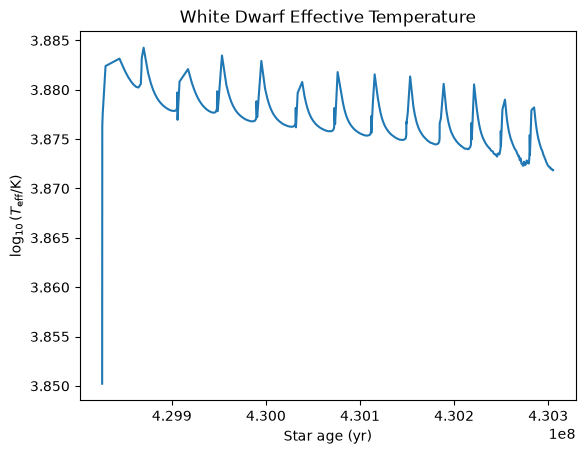

In [12]:
import matplotlib.pyplot as plt

plt.plot(data["star_age"], data["log_Teff"])
plt.xlabel("Star age (yr)")
plt.ylabel(r"$\log_{10}(T_{\rm eff}/{\rm K})$")
plt.title("White Dwarf Effective Temperature")
plt.show()

In [13]:
print("First model:", data["model_number"][0])
print("Last model:", data["model_number"][-1])

print("Starting age:", data["star_age"][0])
print("Ending age:", data["star_age"][-1])

First model: 981.0
Last model: 10000.0
Starting age: 429825968.90544224
Ending age: 430305205.62885195
